<a href="https://colab.research.google.com/github/yeongwonshin/montecarloSimul/blob/main/delaunay_st.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

def lcg(seed=42, a=21, c=43, m=200, n=20):
    numbers = []
    x = seed # fixed
    for _ in range(n):
        x = (a * x + c) % m
        numbers.append(x)
    return numbers

def get_points(points_2_pairs=20):
    points = {
        'points_1': np.array([
                    [120, 240],
                    [370, 180],
                    [550, 460],
                    [260, 540]
                    ]),
        'points_2': np.reshape(np.array(lcg(n=2*points_2_pairs)),(-1,2))
    }
    return points

[(0, 1, 3), (1, 2, 3)]


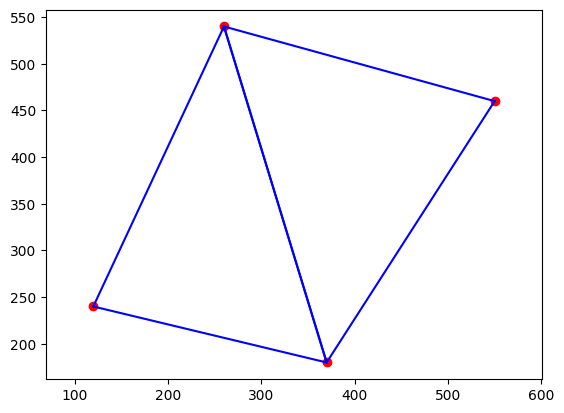

[(2, 6, 9), (6, 8, 9), (4, 7, 10), (3, 5, 11), (4, 7, 11), (1, 9, 12), (0, 10, 12), (0, 10, 13), (2, 9, 15), (9, 12, 15), (0, 12, 15), (2, 13, 15), (0, 13, 15), (8, 9, 16), (1, 9, 16), (2, 6, 17), (6, 14, 17), (2, 13, 17), (3, 5, 18), (1, 16, 18), (5, 8, 18), (8, 16, 18), (4, 11, 19), (3, 11, 19), (1, 12, 19), (4, 10, 19), (10, 12, 19), (3, 18, 19), (1, 18, 19)]


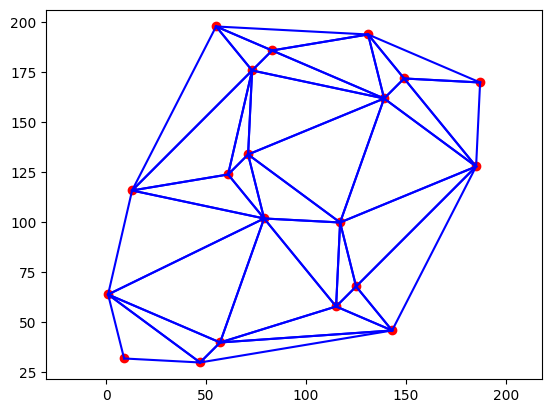

In [ ]:

class DelaunayTriangulation:
    def __init__(self, points):
        self.points = np.asarray(points)
        self.triangles = []

    def makeDelaunay(self):
        points = np.asarray(self.points, dtype=float)
        n = len(points)

        if n < 3:
            self.triangles = []
            return

        min_x, min_y = np.min(points, axis=0)
        max_x, max_y = np.max(points, axis=0)

        dx = max_x - min_x
        dy = max_y - min_y
        d = max(dx, dy, 1.0)

        mid_x = (min_x + max_x) / 2
        mid_y = (min_y + max_y) / 2

        # 1. Super Triangle 생성
        super_triangle = np.array([
            [mid_x - 20 * d, mid_y - d],
            [mid_x + 20 * d, mid_y - d],
            [mid_x, mid_y + 20 * d]
        ])

        all_points = np.vstack((points, super_triangle))
        triangles = [(n, n + 1, n + 2)]

        # 2. 외접원 내부에 점이 존재하는지 검사
        def in_circumcircle(p, tri):
            a, b, c = all_points[list(tri)]

            ax, ay = a - p
            bx, by = b - p
            cx, cy = c - p

            det = (
                (ax * ax + ay * ay) * (bx * cy - cx * by)
                - (bx * bx + by * by) * (ax * cy - cx * ay)
                + (cx * cx + cy * cy) * (ax * by - bx * ay)
            )

            orientation = (
                (b[0] - a[0]) * (c[1] - a[1])
                - (b[1] - a[1]) * (c[0] - a[0])
            )

            if orientation > 0:
                return det > 1e-9
            elif orientation < 0:
                return det < -1e-9
            return False

        # 3. 각 점을 순차적으로 삽입
        for i in range(n):
            p = all_points[i]
            bad_triangles = []

            for tri in triangles:
                if in_circumcircle(p, tri):
                    bad_triangles.append(tri)

            # 4. 제거할 삼각형들의 경계 간선 찾기
            edge_count = {}

            for tri in bad_triangles:
                edges = [
                    (tri[j], tri[(j + 1) % 3])
                    for j in range(3)
                ]

                for edge in edges:
                    edge = tuple(sorted(edge))
                    edge_count[edge] = edge_count.get(edge, 0) + 1

            boundary_edges = [
                edge
                for edge, count in edge_count.items()
                if count == 1
            ]

            # 5. Delaunay 조건을 위반한 삼각형 제거
            bad_set = set(bad_triangles)

            triangles = [
                tri for tri in triangles
                if tri not in bad_set
            ]

            # 6. 경계 간선과 새 점을 연결
            for a, b in boundary_edges:
                triangles.append((a, b, i))

        # 7. Super Triangle의 정점을 포함하는 삼각형 제거
        triangles = [
            tri for tri in triangles
            if all(v < n for v in tri)
        ]

        # 8. 최종 삼각형 저장
        self.triangles = triangles

    def plot(self):
        print(self.triangles)
        plt.figure()

        # 삼각형의 세 변을 그림
        if len(self.triangles) > 0:
            for tri in self.triangles:
                pts = self.points[list(tri)]

                for i in range(3):
                    x = [pts[i][0], pts[(i + 1) % 3][0]]
                    y = [pts[i][1], pts[(i + 1) % 3][1]]
                    plt.plot(x, y, 'b-')

        # 점 표시
        plt.scatter(
            self.points[:, 0],
            self.points[:, 1],
            color='red'
        )

        plt.axis('equal')
        plt.show()


for points in get_points().values():
    dt = DelaunayTriangulation(points)
    dt.makeDelaunay()
    dt.plot()


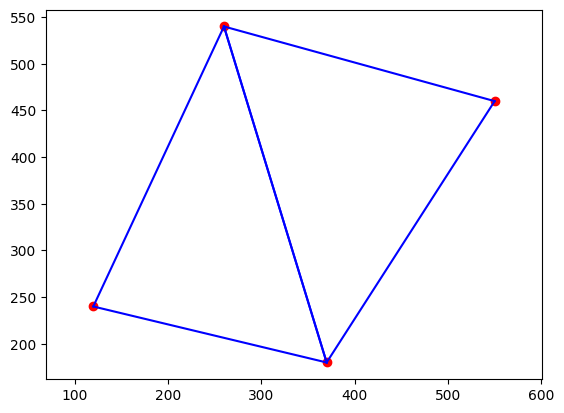

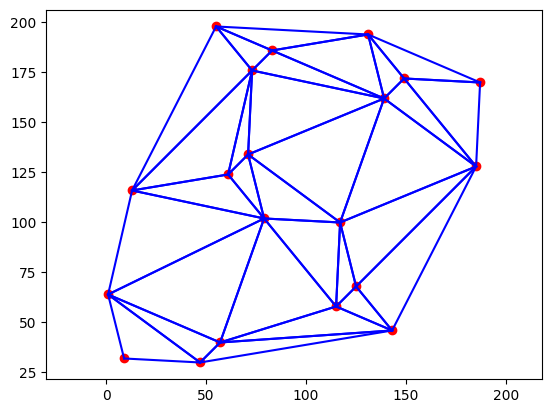

In [ ]:

from scipy.spatial import Delaunay


class DelaunayTriangulation:
    def __init__(self, points):
        self.points = np.asarray(points)
        self.triangles = []

    def makeDelaunay(self):
        if len(self.points) < 3:
            self.triangles = []
            return

        delaunay = Delaunay(self.points)
        self.triangles = delaunay.simplices

    def plot(self):
        plt.figure()
        self.makeDelaunay()

        # self.triangles가 비어있으면 아무것도 연결 안 함
        if len(self.triangles) > 0:
            for tri in self.triangles:
                pts = self.points[tri]

                # 삼각형의 세 변을 직접 그림
                for i in range(3):
                    x = [pts[i][0], pts[(i+1)%3][0]]
                    y = [pts[i][1], pts[(i+1)%3][1]]
                    plt.plot(x, y, 'b-')

        # 점 찍기
        plt.scatter(self.points[:, 0], self.points[:, 1], color='red')
        plt.axis('equal')
        plt.show()


for points in get_points().values():
    dt = DelaunayTriangulation(points)
    dt.plot()


100%|██████████| 9.91M/9.91M [00:00<00:00, 40.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.13MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.89MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.73MB/s]


(5000, 784)


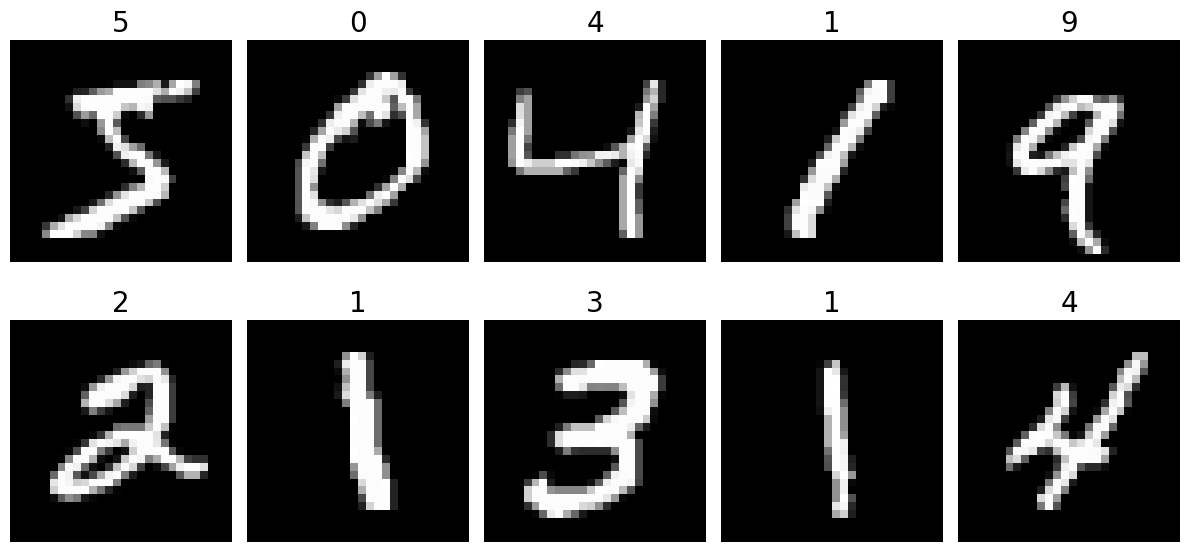

Validation accuracy: 0.938
KNN score: 0.938
k: 1, accuracy: 95.60
k: 2, accuracy: 95.00
k: 3, accuracy: 94.60
k: 4, accuracy: 93.80
k: 5, accuracy: 93.80
k: 6, accuracy: 93.40
k: 7, accuracy: 93.40
k: 8, accuracy: 93.60
k: 9, accuracy: 92.80
k: 10, accuracy: 92.80


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
import torch
from torchvision import datasets, transforms

# Load MNIST dataset using torchvision
transform = transforms.Compose([transforms.ToTensor()])
mnist_data = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# Convert the data into numpy arrays
x_digit = mnist_data.data[:5000].numpy()
y_digit = mnist_data.targets[:5000].numpy()

# Reshape x_digit for the KNN classifier
x_digit = x_digit.reshape(-1, 28 * 28)
print(x_digit.shape)

# Visualize some samples
w, h = 2, 5
fig, axes = plt.subplots(w, h)
fig.set_size_inches(12, 6)

for i in range(w * h):
    axes[i // h, i % h].imshow(
        x_digit[i].reshape(28, 28),
        cmap='gray'
    )
    axes[i // h, i % h].set_title(
        y_digit[i],
        fontsize=20
    )
    axes[i // h, i % h].axis('off')

plt.tight_layout()
plt.show()

# Split the data into train and validation sets
x_train, x_valid, y_train, y_valid = train_test_split(
    x_digit,
    y_digit,
    stratify=y_digit,
    random_state=30,
    test_size=0.1
)

# Initialize and train the KNN classifier
knn = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn.fit(x_train, y_train)
prediction = knn.predict(x_valid)

# Calculate accuracy
print("Validation accuracy:", (prediction == y_valid).mean())
print("KNN score:", knn.score(x_valid, y_valid))

# Experiment with different values of k
for k in range(1, 11):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1
    )

    knn.fit(x_train, y_train)
    score = knn.score(x_valid, y_valid)

    print('k: %d, accuracy: %.2f' % (k, score * 100))
